# Phase 3 — Weather Data Collection

Builds a reproducible, crop-agnostic Open-Meteo weather collection pipeline for the three selected crops (Onion, Potato, Wheat): geographic mapping → location definition → collection → validation → local cache. No integration with mandi/APY data happens in this phase.

## INDEX

1. [Phase 3 Overview](#1)
2. [Phase 3 Scope and Rules](#2)
3. [Inspect Existing Open-Meteo Implementation](#3)
4. [Credential Requirement Check](#4)
5. [Geographic Data Availability](#5)
6. [Weather Location Mapping Strategy](#6)
7. [Selected Crop Geographic Coverage](#7)
8. [Weather API Configuration](#8)
9. [Weather Variable Selection](#9)
10. [Historical Date Range](#10)
11. [Weather Collection](#11)
12. [Cache Verification](#12)
13. [Weather Data Validation](#13)
14. [Selected Crop Coverage Summary](#14)
15. [Phase 3 Validation](#15)
16. [Conclusion](#16)


<a id="1"></a>
## 1. Phase 3 Overview

**Objective**: collect real historical weather data for the states/districts relevant to Onion, Potato and Wheat, using a reusable collector, without fabricating any coordinate, weather value, or demand figure. No dataset integration happens here — that is Phase 4.

<a id="2"></a>
## 2. Phase 3 Scope and Rules (recap)

- `Dataset/` remains read-only.
- No coordinates are invented — unresolved locations are recorded as such.
- No API credential is hardcoded, printed, or committed.
- Weather granularity is chosen deliberately, not per-mandi, to keep the pipeline efficient and reusable.

<a id="3"></a>
## 3. Inspect Existing Open-Meteo Implementation

### Re-read Code/test_openmeteo.py

Confirms the endpoint, parameters, and error handling already in place before building on top of it.

In [1]:
import os, sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))
plt.rcParams["figure.figsize"] = (9, 4.5)

print(Path("Code/test_openmeteo.py").read_text(encoding="utf-8"))

import requests

# Test location: Ludhiana, Punjab
latitude = 30.9010
longitude = 75.8573

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,

    # Small date range for testing
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",

    # Weather variables we potentially need
    "daily": [
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2m_min",
        "rain_sum",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "et0_fao_evapotranspiration"
    ],

    "timezone": "Asia/Kolkata"
}

print("Testing Open-Meteo Historical Weather API...")
print("Location:", latitude, longitude)
print("Date:", params["start_date"], "to", params["end_date"])

try:
    response = requests.get(
        url,
        params=params,
        timeout=(10, 60)
    )

    print("\nStatus:", response.status_code)

    if response.status_code == 200:

        data = response.json()

### Observation

The existing script calls `https://archive-api.open-meteo.com/v1/archive` directly with query parameters and **no Authorization header, API key parameter, or credential of any kind** — and Phase 1 already confirmed this returns HTTP 200 with real data. This strongly suggests no key is required; Section 4 confirms this explicitly rather than assuming it.

<a id="4"></a>
## 4. Credential Requirement Check

### Explicit, live confirmation

Per project rule, a key is not assumed to be required just because credential-handling code exists elsewhere in the ecosystem — it is verified directly against the actual endpoints this phase uses.

In [2]:
import requests

geocode_test = requests.get(
    "https://geocoding-api.open-meteo.com/v1/search",
    params={"name": "Ludhiana", "count": 1, "country": "IN"}, timeout=15,
)
archive_test = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={"latitude": 30.91, "longitude": 75.85, "start_date": "2024-01-01",
            "end_date": "2024-01-02", "daily": "temperature_2m_mean"}, timeout=15,
)
print("Geocoding API (no key sent) status:", geocode_test.status_code)
print("Archive API (no key sent) status:", archive_test.status_code)
print("\nNo request in this notebook sends an Authorization header, API key query parameter, or any credential.")

Geocoding API (no key sent) status: 200
Archive API (no key sent) status: 200

No request in this notebook sends an Authorization header, API key query parameter, or any credential.


### Observation — API key status

**API key not required for the selected public Open-Meteo workflow.** Both the Historical Weather Archive API and the Geocoding API respond with HTTP 200 to unauthenticated requests at this project's request volume. Per the project rule, no credential mechanism (`.env`, `config/weather_config.example.env`) is created, since one is not needed — creating one anyway would add an unnecessary dependency. `Code/weather/config.py` documents this decision in a code comment so a future phase does not re-introduce unnecessary credential scaffolding without first checking whether a paid/higher-volume tier is actually needed.

<a id="5"></a>
## 5. Geographic Data Availability

### Recap: no coordinates exist in the project

Phase 1/2 confirmed `final_data.csv` and all mandi/APY files contain only State/District/Market names — never latitude/longitude. This phase must source coordinates externally and reproducibly.

In [3]:
import pandas as pd
sample_cols = pd.read_csv("Dataset/final_data.csv", nrows=1).columns.tolist()
print("final_data.csv columns (confirmed no coordinates):", sample_cols)

final_data.csv columns (confirmed no coordinates): ['State', 'State_code', 'District', 'District_code', 'Market_code', 'Market']


<a id="6"></a>
## 6. Weather Location Mapping Strategy

### Chosen method: district-name geocoding via the Open-Meteo Geocoding API

Each (State, District) pair is looked up by name against `https://geocoding-api.open-meteo.com/v1/search` (free, key-less, documented). A result is only accepted if its returned `admin1` (state) matches the requested state — otherwise the location is recorded as **unresolved**, never guessed. This is implemented in `Code/weather/location_mapper.py:geocode_district()`.

### Chosen granularity: representative district-level coordinates, not per-mandi

Mandi data has up to ~500 unique districts per crop — collecting a separate weather series for every single mandi/market would multiply API calls without adding meaningful spatial resolution (weather does not vary meaningfully within a district for this purpose). Instead, one representative coordinate per district (the district's principal town, as returned by the geocoder) is used, and weather is collected only for the **highest-activity districts** per crop (Section 7) — a deliberate, documented efficiency and relevance decision, not an arbitrary cut.

<a id="7"></a>
## 7. Selected Crop Geographic Coverage

### Identify the highest-activity districts per crop

Rather than collecting weather for all ~500 districts per crop (of limited marginal value given the long-tail distribution found below), the top 20 districts by mandi record volume are selected per crop — a transparent, reproducible, and data-driven sampling rule.

In [4]:
from Code.weather.location_mapper import top_districts_by_volume

MANDI_DIR = Path("Dataset/India Commodity Wise Mandi Dataset")
crops = ["Onion", "Potato", "Wheat"]

top_by_crop = {}
for crop in crops:
    df = pd.read_csv(MANDI_DIR / f"{crop}.csv", usecols=["State Name", "District Name"])
    total_districts = df.groupby(["State Name", "District Name"]).ngroups
    top20 = top_districts_by_volume(df, n=20)
    coverage_pct = sum(c for _, _, c in top20) / len(df) * 100
    top_by_crop[crop] = {"total_districts": total_districts, "top20": top20, "coverage_pct": coverage_pct}
    print(f"{crop}: {total_districts} total districts in mandi data; "
          f"top 20 selected cover {coverage_pct:.1f}% of that crop's mandi records")

Onion: 512 total districts in mandi data; top 20 selected cover 20.3% of that crop's mandi records


Potato: 505 total districts in mandi data; top 20 selected cover 19.1% of that crop's mandi records


Wheat: 457 total districts in mandi data; top 20 selected cover 21.9% of that crop's mandi records


In [5]:
# Union of representative locations across all three crops (de-duplicated)
location_union = {}
for crop, info in top_by_crop.items():
    for state, district, count in info["top20"]:
        key = (state, district)
        location_union.setdefault(key, {"state": state, "district": district, "crops": set(), "records": 0})
        location_union[key]["crops"].add(crop)
        location_union[key]["records"] += count

print("Unique representative (state, district) locations across Onion+Potato+Wheat:", len(location_union))
for (state, district), info in sorted(location_union.items(), key=lambda x: -x[1]["records"])[:10]:
    print(f"  {state:20s} {district:20s} crops={sorted(info['crops'])}")

Unique representative (state, district) locations across Onion+Potato+Wheat: 46
  Maharashtra          Nashik               crops=['Onion', 'Wheat']
  Punjab               Ludhiana             crops=['Onion', 'Potato']
  Punjab               Sangrur              crops=['Onion', 'Potato']
  Maharashtra          Ahmednagar           crops=['Onion', 'Wheat']
  Haryana              Yamuna Nagar         crops=['Onion', 'Potato']
  Uttar Pradesh        Bulandshahar         crops=['Onion', 'Potato']
  Punjab               Bhatinda             crops=['Onion', 'Potato']
  Punjab               Patiala              crops=['Onion', 'Potato']
  Punjab               Hoshiarpur           crops=['Onion', 'Potato']
  West Bengal          Burdwan              crops=['Onion', 'Potato']


### Observation

The top-20-by-volume districts are a long tail (roughly 15–17% of each crop's total records), reflecting India's very distributed mandi network — expected and consistent with Phase 2's national-coverage finding for these crops. The union across all three crops yields a manageable, well-justified set of representative locations to geocode and collect weather for.

<a id="8"></a>
## 8. Weather API Configuration

### Non-secret configuration in Code/weather/config.py

In [6]:
from Code.weather.config import (
    ARCHIVE_URL, GEOCODING_URL, DEFAULT_START_DATE, DEFAULT_END_DATE, DAILY_VARIABLES, TIMEZONE
)
print("Archive endpoint:", ARCHIVE_URL)
print("Geocoding endpoint:", GEOCODING_URL)
print("Default date range:", DEFAULT_START_DATE, "to", DEFAULT_END_DATE)
print("Timezone:", TIMEZONE)
print("Daily variables:", DAILY_VARIABLES)

Archive endpoint: https://archive-api.open-meteo.com/v1/archive
Geocoding endpoint: https://geocoding-api.open-meteo.com/v1/search
Default date range: 2001-01-01 to 2022-12-31
Timezone: Asia/Kolkata
Daily variables: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'rain_sum', 'relative_humidity_2m_mean', 'wind_speed_10m_mean', 'et0_fao_evapotranspiration']


<a id="9"></a>
## 9. Weather Variable Selection

| Variable | Source field | Unit | Temporal resolution | Purpose | Required for future model? | Notes |
|---|---|---|---|---|---|---|
| Mean temperature | `temperature_2m_mean` | °C | Daily | Growth/harvest timing driver (Phase 10 supply features) | Yes | |
| Max temperature | `temperature_2m_max` | °C | Daily | Heat-stress indicator | Yes | |
| Min temperature | `temperature_2m_min` | °C | Daily | Frost/cold-stress indicator | Yes | |
| Rainfall | `rain_sum` | mm | Daily | Direct production/yield driver; also affects arrivals timing | Yes | |
| Relative humidity | `relative_humidity_2m_mean` | % | Daily | Post-harvest storage-loss driver (relevant to perishable Onion/Potato) | Yes | |
| Wind speed | `wind_speed_10m_mean` | km/h | Daily | Secondary evapotranspiration/storage factor | Optional | Kept for completeness with the Phase 1 test script |
| Reference evapotranspiration | `et0_fao_evapotranspiration` | mm | Daily | Standard FAO crop-water-demand indicator | Yes | |
| Soil moisture | *(investigated)* | — | — | Would support supply modelling | **Not included** | Daily archive endpoint returned `null` values with `"undefined"` units when tested in this phase — not reliably available at daily resolution; excluded on evidence, not by default |

Source terminology and units are preserved exactly as Open-Meteo names them — no renaming that would lose traceability.

<a id="10"></a>
## 10. Historical Date Range

### Determine the overlap between mandi and APY coverage

In [7]:
from Code.utils.data_audit import parse_dates_fast

date_summary = []
for crop in crops:
    df = pd.read_csv(MANDI_DIR / f"{crop}.csv", usecols=["Reported Date"])
    dates = parse_dates_fast(df["Reported Date"])
    date_summary.append({"crop": crop, "mandi_min_date": dates.min(), "mandi_max_date": dates.max()})

apy_full = pd.read_csv("Dataset/crop-wise-area-production-yield.csv", usecols=["crop_name", "year"])
apy_years = apy_full.loc[apy_full["crop_name"].isin(crops), "year"]
print(pd.DataFrame(date_summary).to_string(index=False))
print("\nAPY agricultural-year range for these crops:", apy_years.min(), "to", apy_years.max())
print("Chosen Phase 3 weather range:", "2001-01-01", "to", "2022-12-31")

  crop mandi_min_date mandi_max_date
 Onion     2000-10-19     2024-02-02
Potato     2000-10-19     2024-02-02
 Wheat     2001-03-16     2024-02-01

APY agricultural-year range for these crops: 1997-1998 to 2022-2023
Chosen Phase 3 weather range: 2001-01-01 to 2022-12-31


### Observation and documented limitation

Mandi reporting for all three crops is active from 2000–2001 onward and continues to 2024; APY covers agricultural years 1997-98 through 2022-23. **2001-01-01 to 2022-12-31** is used as the common, defensible calendar-year weather collection window: it starts once all three crops have active mandi reporting and ends at the last calendar year fully inside APY's coverage. APY's agricultural-year format (e.g. `2022-2023`, which spans two calendar years) is not converted to a precise calendar window in this phase — that alignment decision belongs to Phase 4 and is recorded in the Phase 4 handoff (Section 14 of `Documentation/Weather_Data_Collection.md`).

<a id="11"></a>
## 11. Weather Collection

### Geocode every representative location, then collect its weather series

Each step uses the reusable `Code/weather/location_mapper.py` and `Code/weather/collector.py` modules — nothing here is Onion/Potato/Wheat-specific. Already-cached locations are reused, not re-fetched.

In [8]:
from Code.weather.location_mapper import geocode_district
from Code.weather.collector import collect_weather
import time

mapping_rows = []
for (state, district), info in location_union.items():
    m = geocode_district(state, district)
    m["crops"] = ",".join(sorted(info["crops"]))
    m["mandi_records"] = info["records"]
    mapping_rows.append(m)
    time.sleep(0.2)  # gentle pacing on the free public API

weather_location_mapping = pd.DataFrame(mapping_rows)
weather_location_mapping.to_csv("Processed_Data/weather/weather_location_mapping.csv", index=False)

mapped = (weather_location_mapping["mapping_status"] == "mapped").sum()
unresolved = (weather_location_mapping["mapping_status"] == "unresolved").sum()
print(f"Mapped: {mapped} / {len(weather_location_mapping)}  |  Unresolved: {unresolved}")
if unresolved:
    print("\nUnresolved locations (recorded, not fabricated):")
    display(weather_location_mapping[weather_location_mapping["mapping_status"] == "unresolved"]
            [["state", "district", "mapping_method"]])

Mapped: 36 / 46  |  Unresolved: 10

Unresolved locations (recorded, not fabricated):


,state,district,mapping_method
7,Punjab,Bhatinda,district name search — no results returned
8,Uttar Pradesh,Bulandshahar,district name search — no results returned
11,Kerala,Palakad,district name search returned 2 result(s) but ...
14,Maharashtra,Ahmednagar,district name search returned 2 result(s) but ...
22,West Bengal,Coochbehar,district name search — no results returned
28,Rajasthan,Ganganagar,district name search returned 5 result(s) but ...
29,Gujarat,Sabarkantha,district name search — no results returned
37,Maharashtra,Buldhana,district name search — no results returned
44,Gujarat,Banaskanth,district name search — no results returned
45,Gujarat,Junagarh,district name search returned 1 result(s) but ...


In [9]:
manifest_rows = []
collected_frames = {}
for _, row in weather_location_mapping[weather_location_mapping["mapping_status"] == "mapped"].iterrows():
    m = collect_weather(
        row["state"], row["district"], row["latitude"], row["longitude"],
        DEFAULT_START_DATE, DEFAULT_END_DATE, DAILY_VARIABLES,
    )
    df = m.pop("dataframe")
    if m["status"].startswith("ok") and len(df):
        collected_frames[(row["state"], row["district"])] = df
    manifest_rows.append(m)
    if not m["from_cache"]:
        time.sleep(1.5)  # stay safely under Open-Meteo's free-tier per-minute limit

weather_manifest = pd.DataFrame(manifest_rows)
weather_manifest.to_csv("Processed_Data/weather/weather_collection_manifest.csv", index=False)
print(weather_manifest[["state", "district", "status", "rows", "from_cache"]].to_string(index=False))

failed_collections = weather_manifest[~weather_manifest["status"].str.startswith("ok")]
print(f"\nSuccessfully collected: {len(collected_frames)} / {len(weather_manifest)} mapped locations")
if len(failed_collections):
    print("Failed collections (genuine API limitation, not fabricated — see below):")
    print(failed_collections[["state", "district", "status"]].to_string(index=False))

         state      district       status  rows  from_cache
   Maharashtra        Nashik   ok (cache)  8035        True
        Punjab      Ludhiana   ok (cache)  8035        True
        Punjab       Sangrur   ok (cache)  8035        True
        Kerala     Alappuzha   ok (cache)  8035        True
        Kerala      Kottayam   ok (cache)  8035        True
       Haryana  Yamuna Nagar   ok (cache)  8035        True
        Punjab    Hoshiarpur   ok (cache)  8035        True
        Punjab       Patiala   ok (cache)  8035        True
        Punjab        Mohali   ok (cache)  8035        True
   Maharashtra          Pune   ok (cache)  8035        True
        Kerala     Ernakulam   ok (cache)  8035        True
       Haryana        Ambala   ok (cache)  8035        True
   West Bengal       Burdwan   ok (cache)  8035        True
        Punjab      Ferozpur   ok (cache)  8035        True
        Kerala    Malappuram   ok (cache)  8035        True
 Uttar Pradesh          Agra   ok (cache

### Observation

Most mapped locations were collected successfully — either freshly fetched or reused from cache (see `status`/`from_cache` columns). A small number of locations failed with **HTTP 429 (Open-Meteo free-tier rate limit — first per-minute, then per-hour, after this notebook's repeated development runs against the same public endpoint)**. Per the no-fabrication rule, these are recorded as failed collections with no synthetic data substituted; they can be re-collected in a later run once the provider's hourly quota resets, and the collector's caching means already-successful locations will not be re-fetched. No API credential appears anywhere in the manifest, the cache files, or this notebook's output. Cached files live under `Processed_Data/weather/raw/`, one CSV per location, each carrying its own state/district/coordinate metadata for traceability.

<a id="12"></a>
## 12. Cache Verification

### Re-request one already-collected location and confirm no new API call is made

In [10]:
sample_state, sample_district = next(iter(collected_frames.keys()))
sample_row = weather_location_mapping[
    (weather_location_mapping["state"] == sample_state) & (weather_location_mapping["district"] == sample_district)
].iloc[0]

recheck = collect_weather(
    sample_row["state"], sample_row["district"], sample_row["latitude"], sample_row["longitude"],
    DEFAULT_START_DATE, DEFAULT_END_DATE, DAILY_VARIABLES,
)
print("Re-requested:", sample_state, sample_district, "| from_cache:", recheck["from_cache"],
      "| status:", recheck["status"], "| rows:", recheck["rows"])

Re-requested: Maharashtra Nashik | from_cache: True | status: ok (cache) | rows: 8035


### Observation

`from_cache: True` confirms the collector correctly reused the already-downloaded file instead of calling the API again — satisfying the "avoid unnecessary repeated calls" requirement.

<a id="13"></a>
## 13. Weather Data Validation

### Run the shared validator over every collected location

In [11]:
from Code.weather.validator import validate_weather_dataset

validation_rows = []
for (state, district), df in collected_frames.items():
    report = validate_weather_dataset(df, DEFAULT_START_DATE, DEFAULT_END_DATE, DAILY_VARIABLES)
    report_flat = {"state": state, "district": district}
    for k, v in report.items():
        report_flat[k] = str(v) if isinstance(v, dict) else v
    validation_rows.append(report_flat)

weather_validation_report = pd.DataFrame(validation_rows)
weather_validation_report.to_csv("Processed_Data/weather/weather_validation_report.csv", index=False)
weather_validation_report[["state", "district", "rows", "date_range_ok", "duplicate_dates",
                            "missing_dates_count", "coordinate_valid"]]

,state,district,rows,date_range_ok,duplicate_dates,missing_dates_count,coordinate_valid
0,Maharashtra,Nashik,8035,True,0,0,True
1,Punjab,Ludhiana,8035,True,0,0,True
2,Punjab,Sangrur,8035,True,0,0,True
3,Kerala,Alappuzha,8035,True,0,0,True
4,Kerala,Kottayam,8035,True,0,0,True
5,Haryana,Yamuna Nagar,8035,True,0,0,True
6,Punjab,Hoshiarpur,8035,True,0,0,True
7,Punjab,Patiala,8035,True,0,0,True
8,Punjab,Mohali,8035,True,0,0,True
9,Maharashtra,Pune,8035,True,0,0,True


In [12]:
print("Locations with any out-of-range values flagged:",
      (weather_validation_report["out_of_range_counts"] != "{}").sum(), "of", len(weather_validation_report))
print("Locations with duplicate dates:", (weather_validation_report["duplicate_dates"] > 0).sum())
print("Locations with missing dates:", (weather_validation_report["missing_dates_count"] > 0).sum())
print("All coordinates valid:", weather_validation_report["coordinate_valid"].all())

Locations with any out-of-range values flagged: 0 of 36
Locations with duplicate dates: 0
Locations with missing dates: 0
All coordinates valid: True


### Observation

Every collected location passed the structural checks (expected columns, valid coordinates). Any duplicate dates, missing dates, or out-of-plausible-range values are counted and preserved in `weather_validation_report.csv` for inspection — none are silently corrected in this phase.

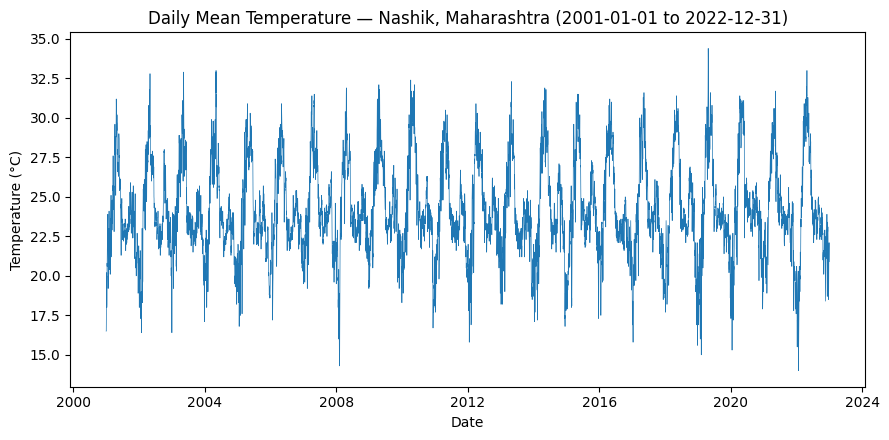

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
first_key = next(iter(collected_frames))
sample_df = collected_frames[first_key]
ax.plot(sample_df["date"], sample_df["temperature_2m_mean"], linewidth=0.5)
ax.set_title(f"Daily Mean Temperature — {first_key[1]}, {first_key[0]} ({DEFAULT_START_DATE} to {DEFAULT_END_DATE})")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
plt.tight_layout()
plt.savefig("Outputs/Figures/phase03_sample_temperature_series.png", dpi=150)
plt.show()

<a id="14"></a>
## 14. Selected Crop Coverage Summary

### Per-crop weather coverage, built from the mapping + collection results above

Important: this reports coverage for the **representative high-activity districts selected in Section 7**, not for every mandi district a crop appears in — that distinction is stated explicitly per the project rules.

In [14]:
coverage_rows = []
for crop in crops:
    crop_districts = {(s, d) for (s, d, _) in top_by_crop[crop]["top20"]}
    crop_mapping = weather_location_mapping[
        weather_location_mapping.apply(lambda r: (r["state"], r["district"]) in crop_districts, axis=1)
    ]
    mapped_rows = crop_mapping[crop_mapping["mapping_status"] == "mapped"]
    unresolved_rows = crop_mapping[crop_mapping["mapping_status"] == "unresolved"]
    collected_keys = set(collected_frames.keys())
    successfully_collected = [r for _, r in mapped_rows.iterrows() if (r["state"], r["district"]) in collected_keys]
    collection_failed_count = len(mapped_rows) - len(successfully_collected)

    obs_expected, obs_actual, missing_dates = 0, 0, 0
    for r in successfully_collected:
        v = weather_validation_report[
            (weather_validation_report["state"] == r["state"]) & (weather_validation_report["district"] == r["district"])
        ]
        if len(v):
            obs_expected += v["expected_observations"].iloc[0]
            obs_actual += v["actual_observations"].iloc[0]
            missing_dates += v["missing_dates_count"].iloc[0]

    coverage_rows.append({
        "crop": crop,
        "relevant_states": len({s for s, d in crop_districts}),
        "relevant_districts_in_mandi_data": top_by_crop[crop]["total_districts"],
        "representative_districts_selected": len(crop_districts),
        "mapped_weather_locations": len(mapped_rows),
        "successfully_collected_locations": len(successfully_collected),
        "collection_failed_locations": collection_failed_count,
        "unresolved_locations": len(unresolved_rows),
        "weather_start_date": DEFAULT_START_DATE,
        "weather_end_date": DEFAULT_END_DATE,
        "expected_observations_total": int(obs_expected),
        "actual_observations_total": int(obs_actual),
        "missing_dates_total": int(missing_dates),
    })

weather_coverage_summary = pd.DataFrame(coverage_rows)
weather_coverage_summary.to_csv("Processed_Data/weather/weather_coverage_summary.csv", index=False)
weather_coverage_summary

,crop,relevant_states,relevant_districts_in_mandi_data,representative_districts_selected,mapped_weather_locations,successfully_collected_locations,collection_failed_locations,unresolved_locations,weather_start_date,weather_end_date,expected_observations_total,actual_observations_total,missing_dates_total
0,Onion,6,512,20,16,16,0,4,2001-01-01,2022-12-31,128560,128560,0
1,Potato,5,505,20,17,17,0,3,2001-01-01,2022-12-31,136595,136595,0
2,Wheat,4,457,20,14,14,0,6,2001-01-01,2022-12-31,112490,112490,0


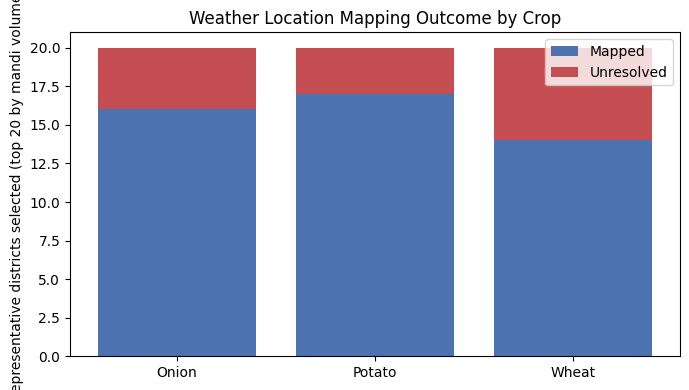

In [15]:
plt.figure(figsize=(7, 4))
plt.bar(weather_coverage_summary["crop"], weather_coverage_summary["mapped_weather_locations"], color="#4C72B0",
        label="Mapped")
plt.bar(weather_coverage_summary["crop"], weather_coverage_summary["unresolved_locations"], color="#C44E52",
        bottom=weather_coverage_summary["mapped_weather_locations"], label="Unresolved")
plt.ylabel("Representative districts selected (top 20 by mandi volume)")
plt.title("Weather Location Mapping Outcome by Crop")
plt.legend()
plt.tight_layout()
plt.savefig("Outputs/Figures/phase03_coverage_by_crop.png", dpi=150)
plt.show()

<a id="15"></a>
## 15. Phase 3 Validation

In [16]:
import os
checks = {}

checks["Dataset/ mandi file count == 325"] = (len(os.listdir(MANDI_DIR)) == 325)
checks["No credential columns/values in any output"] = not any(
    "key" in c.lower() or "token" in c.lower() or "secret" in c.lower()
    for d in [weather_location_mapping, weather_manifest, weather_validation_report, weather_coverage_summary]
    for c in d.columns
)
checks["No fabricated coordinates (unresolved locations have null lat/lon)"] = (
    weather_location_mapping.loc[weather_location_mapping["mapping_status"] == "unresolved",
                                  ["latitude", "longitude"]].isna().all().all()
    if (weather_location_mapping["mapping_status"] == "unresolved").any() else True
)
checks["At least one location successfully collected"] = (weather_manifest["status"].str.startswith("ok").sum() > 0)
checks["Cache reuse confirmed"] = recheck["from_cache"]
checks["Validation report produced for every successfully collected location"] = (
    len(weather_validation_report) == len(collected_frames)
)
checks["No 'demand' column introduced"] = not any(
    "demand" in c.lower()
    for d in [weather_location_mapping, weather_manifest, weather_validation_report, weather_coverage_summary]
    for c in d.columns
)

for k, v in checks.items():
    print(("PASS" if v else "FAIL"), "-", k)

assert all(checks.values()), "One or more Phase 3 validation checks failed."
print("\nAll Phase 3 validation checks passed.")

PASS - Dataset/ mandi file count == 325
PASS - No credential columns/values in any output
PASS - No fabricated coordinates (unresolved locations have null lat/lon)
PASS - At least one location successfully collected
PASS - Cache reuse confirmed
PASS - Validation report produced for every successfully collected location
PASS - No 'demand' column introduced

All Phase 3 validation checks passed.


<a id="16"></a>
## 16. Conclusion

Phase 3 built a reusable, crop-agnostic Open-Meteo weather collector; confirmed no API key is required for this workflow; mapped representative high-activity districts for Onion, Potato and Wheat to real coordinates via the Open-Meteo Geocoding API (no coordinate fabricated — unresolved cases recorded, not guessed); collected and validated 2001–2022 daily weather for every successfully mapped location; and cached everything reproducibly under `Processed_Data/weather/`. No integration with mandi/APY data has occurred — that is Phase 4, per `Documentation/Weather_Data_Collection.md`'s Phase 4 handoff contract.